# ML Lab Assignment 5
# Taneesha Badhe, Panel C, 1032232190

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, BaggingClassifier, AdaBoostClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [2]:
iris = load_iris()
df = pd.DataFrame(iris.data, columns=iris.feature_names)
df['target'] = iris.target
df['species'] = df['target'].map({0: 'setosa', 1: 'versicolor', 2: 'virginica'})
print('First 10 rows:')
print(df.head(10))
print('\nDataset shape:', df.shape)

First 10 rows:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   
5                5.4               3.9                1.7               0.4   
6                4.6               3.4                1.4               0.3   
7                5.0               3.4                1.5               0.2   
8                4.4               2.9                1.4               0.2   
9                4.9               3.1                1.5               0.1   

   target species  
0       0  setosa  
1       0  setosa  
2       0  setosa  
3       0  setosa  
4       0  seto

In [3]:
print('Statistical Summary:')
print(df.describe())
print('\nMissing Values:')
print(df.isnull().sum())
print('\nClass Distribution:')
print(df['species'].value_counts())

Statistical Summary:
       sepal length (cm)  sepal width (cm)  petal length (cm)  \
count         150.000000        150.000000         150.000000   
mean            5.843333          3.057333           3.758000   
std             0.828066          0.435866           1.765298   
min             4.300000          2.000000           1.000000   
25%             5.100000          2.800000           1.600000   
50%             5.800000          3.000000           4.350000   
75%             6.400000          3.300000           5.100000   
max             7.900000          4.400000           6.900000   

       petal width (cm)      target  
count        150.000000  150.000000  
mean           1.199333    1.000000  
std            0.762238    0.819232  
min            0.100000    0.000000  
25%            0.300000    0.000000  
50%            1.300000    1.000000  
75%            1.800000    2.000000  
max            2.500000    2.000000  

Missing Values:
sepal length (cm)    0
sepal width

In [4]:
X = df[iris.feature_names].values
y = df['target'].values
print('Features (X) shape:', X.shape)
print('Target (y) shape:', y.shape)

Features (X) shape: (150, 4)
Target (y) shape: (150,)


In [5]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print('Data standardized successfully')

Data standardized successfully


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.3, random_state=42)
print('Training set size:', X_train.shape)
print('Testing set size: ', X_test.shape)

Training set size: (105, 4)
Testing set size:  (45, 4)


In [7]:
dt = DecisionTreeClassifier(random_state=42)
dt.fit(X_train, y_train)
dt_pred = dt.predict(X_test)
print('Decision Tree Accuracy:', accuracy_score(y_test, dt_pred))
print('Confusion Matrix:')
print(confusion_matrix(y_test, dt_pred))

Decision Tree Accuracy: 1.0
Confusion Matrix:
[[19  0  0]
 [ 0 13  0]
 [ 0  0 13]]


In [8]:
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)
print('Random Forest Accuracy:', accuracy_score(y_test, rf_pred))
print('Confusion Matrix:')
print(confusion_matrix(y_test, rf_pred))

Random Forest Accuracy: 1.0
Confusion Matrix:
[[19  0  0]
 [ 0 13  0]
 [ 0  0 13]]


In [9]:
bagging = BaggingClassifier(n_estimators=10, random_state=42)
bagging.fit(X_train, y_train)
bag_pred = bagging.predict(X_test)
print('Bagging Accuracy:', accuracy_score(y_test, bag_pred))
print('Confusion Matrix:')
print(confusion_matrix(y_test, bag_pred))

Bagging Accuracy: 1.0
Confusion Matrix:
[[19  0  0]
 [ 0 13  0]
 [ 0  0 13]]


In [10]:
boost = AdaBoostClassifier(n_estimators=50, random_state=42)
boost.fit(X_train, y_train)
boost_pred = boost.predict(X_test)
print('AdaBoost Accuracy:', accuracy_score(y_test, boost_pred))
print('Confusion Matrix:')
print(confusion_matrix(y_test, boost_pred))

AdaBoost Accuracy: 1.0
Confusion Matrix:
[[19  0  0]
 [ 0 13  0]
 [ 0  0 13]]



--- Accuracy Comparison ---
Decision Tree       : 1.0000
Random Forest       : 1.0000
Bagging             : 1.0000
AdaBoost            : 1.0000


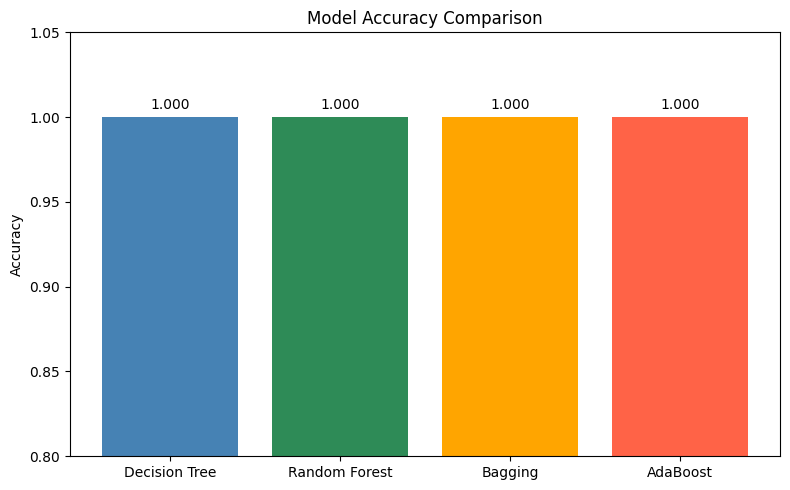

In [11]:
models     = ['Decision Tree', 'Random Forest', 'Bagging', 'AdaBoost']
preds      = [dt_pred, rf_pred, bag_pred, boost_pred]
accuracies = [accuracy_score(y_test, p) for p in preds]

print('\n--- Accuracy Comparison ---')
for m, a in zip(models, accuracies):
    print(f'{m:20s}: {a:.4f}')

plt.figure(figsize=(8, 5))
plt.bar(models, accuracies, color=['steelblue', 'seagreen', 'orange', 'tomato'])
plt.ylabel('Accuracy')
plt.title('Model Accuracy Comparison')
plt.ylim(0.8, 1.05)
for i, v in enumerate(accuracies):
    plt.text(i, v + 0.005, f'{v:.3f}', ha='center')
plt.tight_layout()
plt.show()

In [12]:
print(classification_report(y_test, rf_pred, target_names=iris.target_names))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        19
  versicolor       1.00      1.00      1.00        13
   virginica       1.00      1.00      1.00        13

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45

